# 03 · 一个周期，全部拆开：会计、配给与"钱到哪里去了"

这是六个 notebook 里最重要的一个。它的承诺很简单，也很难做到：

> **本 notebook 里的每一个数字都要算两遍** —— 一遍由 PlanLab 的引擎算，一遍由本 notebook 里**你自己能读懂的显式代码**算。两边必须完全一致（1e-12 相对误差），否则就是 bug，而不是"四舍五入"。

先把话说清楚：这个模型里**没有货币、没有金融**，所有量都是"不变价价值单位"（百万欧元）。所以"价值不会凭空产生或消失"不是比喻，而是一条可以对出来的会计恒等式：

$$S_{0,i} + x_i \;=\; \underbrace{\sum_j Z_{ij}}_{\text{中间使用}} + C_i + G_i + I_i + S_{\text{end},i}$$

其中 `S0` 是期初库存、`x` 是本期产出、`C/G/I` 是居民/政府/投资交付、`S_end` 是期末库存。引擎每期都审计这条式子，误差超过 `1e-8` 相对值就抛 `AccountingError`。

*This is the flagship notebook. Every number is computed twice — once by the engine, once by explicit code in the notebook — and the two must agree to 1e-12. The accounting identity above is audited by the engine every period and by this notebook, line by line.*

**阅读路径**：第 1–5 节用一个 3 部门、全是整数的小经济把每一步手算出来（你可以拿纸核对）；第 6 节把同样的步骤搬到真实的 20 部门 Eurostat 数据上，并逐项断言与引擎一致；第 7 节是一张"审计清单"，第 8 节告诉你数字对不上时去哪里找。

*Sections 1–5 walk through a three-sector integer economy you can check on paper. Section 6 repeats the same steps on the real 20-sector table and asserts elementwise agreement with the engine. Section 7 is the audit receipt; section 8 is the debugging guide.*

## 0 · 一个周期里到底发生了什么

引擎的周期顺序（`docs/ARCHITECTURE.md` §5）只有十步，其中**机制只负责三步**，其余七步是物理和会计：

| # | 步骤 | 谁做 | 本 notebook 的位置 |
|---|---|---|---|
| 1 | 冲击：产能、需求、政府、投资 | 外生 | 第 1 节 |
| 2 | 观察：`obs` = 滞后 k 期 + 对数正态噪声 | 引擎 | 第 2 节 |
| 3 | 计划：目标产出 `x*` | **机制** | 第 2 节 |
| 4 | 名义供给：`S0 + min(x*, capacity)` | 引擎 | 第 2 节 |
| 5 | 索取：谁要什么、优先级几档 | **机制** | 第 3 节 |
| 6 | 可行产出：短边规划 `max Σx` | 引擎 | 第 4 节 |
| 7 | 配给：按优先级分剩下的 | 引擎 | 第 5 节 |
| 8 | 会计：`Z, C, G, I, S_end` | 引擎 | 第 5 节 |
| 9 | 审计：恒等式不成立就抛异常 | 引擎 | 第 5、6 节 |
| 10 | 价格：下期价格 | **机制** | 不在本 notebook |

**为什么机制只管三步？** 这是整套实验的识别策略：如果每个机制自带一套会计，那么"计划经济 vs 市场"的比较就会混进"谁的账算得更细"。让引擎独占会计与可行性，机制之间就只剩制度差异。

*The engine owns accounting, feasibility and rationing; a mechanism only sets targets, claims and prices. That division is what makes the mechanism comparison identified.*

下面这个单元格做准备：载入依赖、固定随机种子、定义一个记录审计结果的小工具 `Ledger`。

In [1]:
%matplotlib inline
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("cannot find the PlanLab checkout root (pyproject.toml)")
os.environ.setdefault("PLANLAB_ROOT", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.optimize import linprog

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 3.6),
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.grid": True, "grid.alpha": 0.3,
    "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
np.set_printoptions(precision=6, suppress=True, linewidth=140)

SEED = 0
T0 = time.perf_counter()


class Ledger:
    """Collects audit checks so the notebook ends with one honest receipt."""

    def __init__(self):
        self.rows = []

    def check(self, name, ok, detail=""):
        self.rows.append({"check": name, "ok": bool(ok), "detail": str(detail)})
        if not ok:
            print(f"  !! FAILED: {name}  ({detail})")
        return bool(ok)

    def frame(self):
        return pd.DataFrame(self.rows, columns=["check", "ok", "detail"])


ledger = Ledger()
print("environment ready")
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy.linprog available")

environment ready
numpy 2.2.6 | pandas 2.3.3 | scipy.linprog available


## 1 · 造一个可以用纸笔核对的经济

真实的 20 部门数据没法手算，所以我们先造一个 3 部门、系数全是两位小数的技术：

$$A=\begin{pmatrix}0.1&0.2&0\\0.1&0.1&0.2\\0.2&0.1&0.1\end{pmatrix},
\qquad x^0=\begin{pmatrix}100\\200\\300\end{pmatrix},\qquad
y^0=x^0-Ax^0=\begin{pmatrix}50\\110\\230\end{pmatrix}.$$

列和是 0.4/0.4/0.3，所以 `A` 可生产（第 01 个 notebook 的判据）。三个部门分别叫 `a, b, c`；只有 `a` 的产出是必需品（`essentials = [1,0,0]`）。

然后设定这一期的**冲击与状态**（全部是整数，方便心算）：

| 量 | 值 | 含义 |
|---|---|---|
| 期初库存 `S0` | `[10, 10, 30]` | 三个商品各有多少存货 |
| 产能 `capacity` | `[100, 60, 300]` | 部门 *b* 的产能被砍到基年的 30% |
| 计划目标 `targets` | `[100, 140, 300]` | 计划者想扩张 *b* |
| 居民需求 `demand` | `[50, 110, 230]` | 基年最终需求 |
| 政府 `G` | `[10, 0, 20]` | |
| 投资 `I` | `[5, 5, 5]` | |
| 存货目标 `stock` | `[0, 0, 0]` | 本期不主动补库存 |

注意一个**关键细节**：计划目标 `targets` 是可以超过产能的（这里 *b* 的目标 140 > 产能 60）。计划是"紧绷的"——这正是物资平衡体制的典型特征，也是 `docs/AMENDMENTS.md` 里 H1' 的来源。引擎不会因此报错；它会把上界取成 `min(targets, capacity)`。

*We build a three-sector integer technology, then set an integer shock and state: inventory, a 70% capacity cut in sector b, a target for b that exceeds its capacity, and base-year household demand. Taut plans are allowed; the engine caps the upper bound at ``min(targets, capacity)``.*

In [2]:
from planlab.core.io_model import build_technology
from planlab.core.state import Allocation, Observation, Plan, State

A_toy = np.array([[0.1, 0.2, 0.0],
                  [0.1, 0.1, 0.2],
                  [0.2, 0.1, 0.1]])
x0_toy = np.array([100.0, 200.0, 300.0])
y0_toy = x0_toy - A_toy @ x0_toy
toy = build_technology(
    sectors=["a", "b", "c"], A=A_toy,
    labor=[0.1, 0.1, 0.1], kappa=[2.0, 2.0, 2.0],
    base_output=x0_toy, base_final=y0_toy,
    consumption_weights=[1.2, 1.0, 1.0], essentials=[1, 0, 0],
)
GOODS = list(toy.sectors)

S0 = np.array([10.0, 10.0, 30.0])        # beginning-of-period inventory
CAP = np.array([100.0, 60.0, 300.0])     # capacity after the shock
TARGETS = np.array([100.0, 140.0, 300.0])  # the plan (allowed to exceed capacity)
DEMAND = y0_toy.copy()
GOV = np.array([10.0, 0.0, 20.0])
INVEST = np.array([5.0, 5.0, 5.0])
STOCK = np.zeros(3)

print("A (rows = good i, columns = using sector j):")
print(pd.DataFrame(A_toy, index=GOODS, columns=GOODS).round(3).to_string())
print("\ncolumn sums (intermediate share of each sector's output):",
      np.round(A_toy.sum(axis=0), 3))
print("\nbase output x0:", x0_toy, " base final demand y0:", y0_toy)
print("identity check: max |x0 - A x0 - y0| =", float(np.max(np.abs(x0_toy - A_toy @ x0_toy - y0_toy))))

state = pd.DataFrame({"inventory S0": S0, "capacity": CAP, "plan target x*": TARGETS,
                      "household demand": DEMAND, "gov": GOV, "invest": INVEST,
                      "stock target": STOCK}, index=GOODS)
print("\nthis period's state:")
print(state.to_string())
print(f"\nplan is taut: targets exceed capacity for "
      f"{[str(g) for g in np.array(GOODS)[TARGETS > CAP]]} "
      f"by {[float(v) for v in (TARGETS - CAP)[TARGETS > CAP]]}")

A (rows = good i, columns = using sector j):
     a    b    c
a  0.1  0.2  0.0
b  0.1  0.1  0.2
c  0.2  0.1  0.1

column sums (intermediate share of each sector's output): [0.4 0.4 0.3]

base output x0: [100. 200. 300.]  base final demand y0: [ 50. 110. 230.]
identity check: max |x0 - A x0 - y0| = 0.0

this period's state:
   inventory S0  capacity  plan target x*  household demand   gov  invest  stock target
a          10.0     100.0           100.0              50.0  10.0     5.0           0.0
b          10.0      60.0           140.0             110.0   0.0     5.0           0.0
c          30.0     300.0           300.0             230.0  20.0     5.0           0.0

plan is taut: targets exceed capacity for ['b'] by [80.0]


## 2 · 观察与计划：机制看到的不是现在

`Observation` 是一个普通的 dataclass。它携带的是**统计部门到现在为止能报出来的**数：`t` 期的决策只能用 `t-1-k` 期的已实现结果，然后再叠一层对数正态测量噪声。构造函数 `build_observation` 把这条时序写死：

```python
src = max(0, t - 1 - lag)     # 观察到的期数
meta = {"observed_period": src, "effective_lag": lag + 1}
```

`lag = 0` 不是"全知"，而是"按上季报表做计划"——这是历史上诚实的最好情况。有效延迟是 `lag + 1`，因为已经发生的事要一期之后才可能被统计出来。notebook 02 里的 `m` 就是这里的 `effective_lag`。

下面这个单元格用一段人造历史，直接演示 `lag = 0` 和 `lag = 2` 分别看到哪一期。**注意断言**：观察到的需求向量必须与历史里那一期的需求逐元素相等（噪声为 0 时）。

*An ``Observation`` is a plain dataclass carrying the latest official statistics: at ``t`` the most recent realised outcome available is ``t-1-k``. With zero noise the observed vector must equal the history at exactly that period — which we assert.*

In [3]:
from planlab.core.engine import build_observation

# a synthetic history: demand grows by 10% per quarter so we can tell periods apart
hist = {
    "demand":    [np.array([50.0, 110.0, 230.0]) * (1.10 ** k) for k in range(8)],
    "capacity":  [CAP.copy() for _ in range(8)],
    "inventory": [S0.copy() for _ in range(8)],
    "price":     [np.ones(3) for _ in range(8)],
    "backlog":   [np.zeros(3) for _ in range(8)],
    "labour":    [1.0 for _ in range(8)],
    "shortage":  [np.zeros(3) for _ in range(8)],
}
rng = np.random.default_rng(SEED)
t_now = 6
for lag in (0, 2):
    obs = build_observation(
        t=t_now, lag=lag, noise=0.0, rng=rng, hist=hist,
        observe_capacity=True, observe_inventory=True, observe_backlog=True,
        fallback_capacity=np.zeros(3), fallback_inventory=np.zeros(3),
        fallback_backlog=np.zeros(3), fallback_labour=1.0,
    )
    src = obs.meta["observed_period"]
    print(f"lag = {lag}: at t = {t_now} the planner sees period {src} "
          f"(effective lag m = {obs.meta['effective_lag']}); "
          f"obs.demand = {np.round(obs.demand, 2)}")
    assert np.array_equal(obs.demand, hist["demand"][src]), "observed demand is not the stale one"
print("\nPASS: with lag = k the planner sees t-1-k, i.e. the effective delay is k+1 periods.")
print("      (The docstring of build_observation is the normative statement of this timing.)")

lag = 0: at t = 6 the planner sees period 5 (effective lag m = 1); obs.demand = [ 80.53 177.16 370.42]
lag = 2: at t = 6 the planner sees period 3 (effective lag m = 3); obs.demand = [ 66.55 146.41 306.13]

PASS: with lag = k the planner sees t-1-k, i.e. the effective delay is k+1 periods.
      (The docstring of build_observation is the normative statement of this timing.)


## 3 · 索取矩阵：谁要什么、优先级几档

`Allocation` 是机制交给引擎的唯一凭据。它的行约定是：

* 前 `n` 行是**部门 *j* 的投入需求**（`claims[j, i]` = 部门 *j* 要多少商品 *i*），标签 `inter:jj`；
* 其余行是最终索取者，标签必须以 `final:`、`gov:`、`invest:`、`stock:` 开头；
* `tiers` 给出每行的优先级，**数字小的先被满足**。

默认阶梯（`Allocation.build` 的文档）是：

```
0  中间投入    生产不能饿死
1  final:essential   食品、能源、医疗、运输
2  final:other       非必需消费
3  gov
4  invest
5  stock
```

这条阶梯**不是技术细节，而是有制度内容的建模选择**。把它反过来（消费优先）就是一个可比较的处理，`material_balance` 用参数 `ladder="consumption_first"` 暴露它——第 9 节的练习会让你亲手把它拆掉。

*The claim matrix has one row per sector plus one row per final claimant, with a priority tier per row; lower tiers are served first. The ladder is an institutional choice with modelling content, not an implementation detail.*

下面把这一期的索取矩阵显式构造出来。注意两个层次：

1. **机制提交的**中间需求是基于**计划目标**的：`claims[j] = A[:, j] * targets[j]`——计划者以为会有 `targets` 那么多产出；
2. **引擎实际使用的**中间需求是基于**实现产出**的：`claims[j] = A[:, j] * x[j]`。因为可行产出规划保证了物资平衡，只有按实现产出算的中间需求才可能被满足。

这个差别正是"计划"与"现实"之间的缝。第 4 节会看到引擎怎么把它缝上。

In [4]:
def build_claims(intermediates, final, gov, invest, stock, essentials):
    """Assemble the claim matrix exactly as Allocation.build does, but visibly."""
    rows = [np.asarray(intermediates, float)]
    tiers = [np.zeros(intermediates.shape[0])]
    labels = [f"inter:{j:02d}" for j in range(intermediates.shape[0])]
    mask = np.asarray(essentials) > 0.5
    if mask.any():
        rows.append(np.where(mask, final, 0.0).reshape(1, -1))
        tiers.append(np.array([1.0]))
        labels.append("final:essential")
    if (~mask).any():
        rows.append(np.where(~mask, final, 0.0).reshape(1, -1))
        tiers.append(np.array([2.0]))
        labels.append("final:other")
    rows.append(np.asarray(gov, float).reshape(1, -1));   tiers.append(np.array([3.0])); labels.append("gov:00")
    rows.append(np.asarray(invest, float).reshape(1, -1)); tiers.append(np.array([4.0])); labels.append("invest:00")
    rows.append(np.asarray(stock, float).reshape(1, -1));  tiers.append(np.array([5.0])); labels.append("stock:00")
    return np.vstack(rows), np.concatenate(tiers), tuple(labels)


# the mechanism's view: intermediate requirements computed from PLANNED targets
inter_planned = (A_toy * TARGETS.reshape(1, -1)).T
claims_planned, tiers, labels = build_claims(inter_planned, DEMAND, GOV, INVEST, STOCK, toy.essentials)
print("claims submitted by the mechanism (row = claimant, column = good):")
print(pd.DataFrame(claims_planned, index=labels, columns=GOODS).round(2).to_string())
print("\ntiers:", {lab: int(t) for lab, t in zip(labels, tiers)})
print("\nrow sums of the intermediate block = A @ targets:",
      np.round(claims_planned[:3].sum(axis=0), 2))

# and cross-check against the library constructor on the same inputs
alloc_lib = Allocation.build(intermediates=inter_planned, final=DEMAND, gov=GOV, invest=INVEST,
                             to_inventory=STOCK, essentials=toy.essentials)
assert np.allclose(alloc_lib.claims, claims_planned)
assert np.array_equal(alloc_lib.tiers, tiers)
assert alloc_lib.labels == labels
print("\nPASS: our hand-built claim matrix is identical to Allocation.build on the same inputs.")

claims submitted by the mechanism (row = claimant, column = good):
                    a      b      c
inter:00         10.0   10.0   20.0
inter:01         28.0   14.0   14.0
inter:02          0.0   60.0   30.0
final:essential  50.0    0.0    0.0
final:other       0.0  110.0  230.0
gov:00           10.0    0.0   20.0
invest:00         5.0    5.0    5.0
stock:00          0.0    0.0    0.0

tiers: {'inter:00': 0, 'inter:01': 0, 'inter:02': 0, 'final:essential': 1, 'final:other': 2, 'gov:00': 3, 'invest:00': 4, 'stock:00': 5}

row sums of the intermediate block = A @ targets: [38. 84. 64.]

PASS: our hand-built claim matrix is identical to Allocation.build on the same inputs.


## 4 · 可行产出：短边规划（模型的心脏）

现在进入引擎。给定产能、库存、上界（`min(targets, capacity)`）和劳动供给，**最大的可行产出**由这个小线性规划给出：

$$\max_x \sum_j x_j \quad\text{s.t.}\quad (A-I)x \le S_0,\qquad 0 \le x \le \min(x^*, \text{cap}).$$

第一条约束是逐商品的物资平衡：商品 *i* 的中间使用 `(Ax)_i` 不能超过它的产出 `x_i` 加库存 `S_0i`。第二条是产能与计划的上界。劳动约束本 notebook 里是松弛的（三个部门的劳动系数都很小），真实周期里也基本不紧，但代码里保留。

**为什么用规划而不是"按比例缩小"？** 这是 `docs/ARCHITECTURE.md` §5 里一句话的事，但值得在这里再念一遍：按比例缩小**无法重新配置生产结构**。当部门 *b* 的产能被砍掉 70% 时，正确的反应是**少生产最依赖 *b* 的那个部门 c**，而不是让所有部门一起缩。按比例缩小会收敛到零，规划则会收敛到重新平衡后的计划。

*The short side is a small linear programme: maximise total output subject to the per-good material balance, capacity and the plan's upper bounds. A proportional cascade cannot rebalance the production mix and converges to zero; the programme converges to the rebalanced plan.*

下面把这个规划**逐行打印出来**，用手算求解，再用 `scipy.linprog` 核对。

In [5]:
UB = np.minimum(TARGETS, CAP)
print("upper bounds  ub = min(targets, capacity):", UB)
print("\nthe goods-balance rows (A - I) and their right-hand sides S0:")
lhs = pd.DataFrame(A_toy - np.eye(3), index=GOODS,
                   columns=[f"x_{j}" for j in GOODS]).round(3)
lhs["<= S0"] = S0
print(lhs.to_string())
print("\nWritten out:")
for i, g in enumerate(GOODS):
    terms = " + ".join(f"{A_toy[i, j]:.1f} x_{GOODS[j]}" for j in range(3) if A_toy[i, j] != 0)
    print(f"  good {g}:  ({terms}) - x_{g} <= S0_{g} = {S0[i]:.0f}")
print("\nBy hand: good b is the only scarcer-than-needed one.")
print("  x_a <= 100, x_b <= 60 (capacity), x_c <= 300;")
print("  good b needs 0.1 x_a + 0.1 x_b + 0.2 x_c <= S0_b + x_b = 10 + x_b")
print("  with x_a = 100, x_b = 60 that reads 10 + 6 + 0.2 x_c <= 70  ->  x_c <= 270.")
print("  Hence sum(x) <= 100 + 60 + 270 = 430, and the vector (100, 60, 270) attains it.")
print("  That is a proof of optimality, not an estimate.")

# now let scipy confirm it
res = linprog(-np.ones(3),
              A_ub=np.vstack([A_toy - np.eye(3)]),
              b_ub=S0,
              bounds=[(0.0, float(UB[i])) for i in range(3)],
              method="highs")
x_hand = np.array([100.0, 60.0, 270.0])
print(f"\nlinprog status: {res.message}")
print(f"linprog solution: {np.round(res.x, 9)}")
print(f"hand solution:    {x_hand}")
assert np.allclose(res.x, x_hand, atol=1e-9)
assert abs(-res.fun - 430.0) < 1e-9
print("\nPASS: the hand solution is exactly the LP optimum, total output = 430 (vs 460 if nothing were scarce).")

upper bounds  ub = min(targets, capacity): [100.  60. 300.]

the goods-balance rows (A - I) and their right-hand sides S0:
   x_a  x_b  x_c  <= S0
a -0.9  0.2  0.0   10.0
b  0.1 -0.9  0.2   10.0
c  0.2  0.1 -0.9   30.0

Written out:
  good a:  (0.1 x_a + 0.2 x_b) - x_a <= S0_a = 10
  good b:  (0.1 x_a + 0.1 x_b + 0.2 x_c) - x_b <= S0_b = 10
  good c:  (0.2 x_a + 0.1 x_b + 0.1 x_c) - x_c <= S0_c = 30

By hand: good b is the only scarcer-than-needed one.
  x_a <= 100, x_b <= 60 (capacity), x_c <= 300;
  good b needs 0.1 x_a + 0.1 x_b + 0.2 x_c <= S0_b + x_b = 10 + x_b
  with x_a = 100, x_b = 60 that reads 10 + 6 + 0.2 x_c <= 70  ->  x_c <= 270.
  Hence sum(x) <= 100 + 60 + 270 = 430, and the vector (100, 60, 270) attains it.
  That is a proof of optimality, not an estimate.

linprog status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
linprog solution: [100.  60. 270.]
hand solution:    [100.  60. 270.]

PASS: the hand solution is exactly the LP optimum, total output =

In [6]:
X = x_hand.copy()
need = A_toy @ X
slack = S0 + X - need
table = pd.DataFrame({
    "output x_j": X,
    "capacity": CAP,
    "plan target": TARGETS,
    "output at bound?": np.where(np.isclose(X, UB), "yes", "no"),
    "input requirement (A x)_j": need,
    "supply S0 + x": S0 + X,
    "slack": slack,
}, index=GOODS)
print("the short-side solution, good by good:")
print(table.round(3).to_string())
print("\nA binding good has zero slack; a binding sector has x == min(target, capacity).")
print(f"binding goods   : {list(np.array(GOODS)[np.isclose(slack, 0)])}")
print(f"binding sectors : {list(np.array(GOODS)[np.isclose(X, UB)])}")
print(f"unused capacity : {np.round(UB - X, 2)}  (sector c cannot sell more because of good b)")
assert np.all((A_toy - np.eye(3)) @ X - S0 <= 1e-9)
print("\nPASS: the solution satisfies every goods-balance constraint.")

the short-side solution, good by good:
   output x_j  capacity  plan target output at bound?  input requirement (A x)_j  supply S0 + x  slack
a       100.0     100.0        100.0              yes                       22.0          110.0   88.0
b        60.0      60.0        140.0              yes                       70.0           70.0    0.0
c       270.0     300.0        300.0               no                       53.0          300.0  247.0

A binding good has zero slack; a binding sector has x == min(target, capacity).
binding goods   : [np.str_('b')]
binding sectors : [np.str_('a'), np.str_('b')]
unused capacity : [ 0.  0. 30.]  (sector c cannot sell more because of good b)

PASS: the solution satisfies every goods-balance constraint.


## 5 · 配给与会计：剩下的东西按优先级分

规划保证了**中间投入拿得到**（这是阶梯的第 0 档，也是规划约束的直接含义）。之后剩下的供给 `S0 + x - Ax` 才轮到最终索取者，按阶梯分配：

1. 对每一档，取该档所有索取者之和 `total`；
2. 该档实际能拿到 `alloc = min(total, remaining)`；
3. 档内**按比例**分配：`grant = claim * alloc / total`；
4. 从 `remaining` 中扣掉 `alloc`，进入下一档。

这条规则（`engine.ration_by_priority`）是引擎**唯一**的配给原语。机制之间的差别只在"提交什么索取"和"给几档优先级"，而不在分配算术——这正是比较可识别的原因。

*Intermediates are served first by construction of the programme; the residual is filled good by good in ascending tier order, pro-rata within a tier. This single primitive is the engine's only rationing rule.*

配给完之后，引擎把授予量映射回五种用途，并做最后一步会计：

```
Z = A · diag(x)               中间使用
C = min(居民获得量, demand)    居民消费（不能超过需求）
G = min(政府获得量, gov)       政府消费
I = min(投资获得量, invest)    投资
S_end = S0 + x - (Z + C + G + I)   期末库存（剩下的都进库存）
unmet = max(demand - C, 0)     未满足的居民需求
```

注意 `C/G/I` 上的 `min(·, 需求)`：**授予量可以超过需求，但用途不会超过需求**，多出来的部分回到 `S_end`。这一点在第 6 节的真实周期里会出现（观察到的需求是上一期的，和本期需求不一致），也是"库存变动"这个科目的来源之一。

In [7]:
def ration_by_priority_by_hand(supply, claims, tiers, verbose=True, row_names=None):
    """Fill claims good by good in ascending tier order, pro-rata within a tier.

    Written from the docstring of planlab.core.engine.ration_by_priority; it does
    not import that function.
    """
    supply = np.asarray(supply, float)
    claims = np.asarray(claims, float)
    grants = np.zeros_like(claims)
    remaining = np.maximum(supply, 0.0).copy()
    log = []
    names = list(row_names) if row_names is not None else [f"row{i}" for i in range(claims.shape[0])]
    for tier in np.unique(tiers):
        rows = np.where(tiers == tier)[0]
        block = claims[rows, :]
        total = block.sum(axis=0)
        alloc = np.minimum(total, remaining)
        scale = np.where(total > 0, alloc / np.maximum(total, 1e-300), 0.0)
        grants[rows, :] = block * scale
        log.append({"tier": int(tier),
                    "claimants": ", ".join(names[r] for r in rows),
                    "claimed": total, "granted": alloc,
                    "remaining after": np.maximum(remaining - alloc, 0.0)})
        remaining = np.maximum(remaining - alloc, 0.0)
    if verbose:
        for rec in log:
            print(f"tier {rec['tier']}: {rec['claimants']}")
            print(f"    claimed {np.round(rec['claimed'], 2)}  granted {np.round(rec['granted'], 2)}"
                  f"  remaining {np.round(rec['remaining after'], 2)}")
    return grants, log


# the engine recomputes intermediate claims on the REALISED output before rationing
claims_realised = claims_planned.copy()
claims_realised[:3, :] = (A_toy * X.reshape(1, -1)).T
SUPPLY = S0 + X
print(f"supply available this period  S0 + x = {SUPPLY}")
print(f"intermediate requirement      A x    = {np.round(need, 2)}")
print(f"residual for final claimants         = {np.round(SUPPLY - need, 2)}\n")
grants, rat_log = ration_by_priority_by_hand(SUPPLY, claims_realised, tiers, row_names=labels)
print("\ngrants (row = claimant, column = good):")
print(pd.DataFrame(grants, index=labels, columns=GOODS).round(2).to_string())

from planlab.core.engine import ration_by_priority
assert np.allclose(grants, ration_by_priority(SUPPLY, claims_realised, tiers))
ledger.check("hand rationing == engine rationing", True)
print("\nPASS: identical to planlab.core.engine.ration_by_priority on the same inputs.")

supply available this period  S0 + x = [110.  70. 300.]
intermediate requirement      A x    = [22. 70. 53.]
residual for final claimants         = [ 88.   0. 247.]

tier 0: inter:00, inter:01, inter:02
    claimed [22. 70. 53.]  granted [22. 70. 53.]  remaining [ 88.   0. 247.]
tier 1: final:essential
    claimed [50.  0.  0.]  granted [50.  0.  0.]  remaining [ 38.   0. 247.]
tier 2: final:other
    claimed [  0. 110. 230.]  granted [  0.   0. 230.]  remaining [38.  0. 17.]
tier 3: gov:00
    claimed [10.  0. 20.]  granted [10.  0. 17.]  remaining [28.  0.  0.]
tier 4: invest:00
    claimed [5. 5. 5.]  granted [5. 0. 0.]  remaining [23.  0.  0.]
tier 5: stock:00
    claimed [0. 0. 0.]  granted [0. 0. 0.]  remaining [23.  0.  0.]

grants (row = claimant, column = good):
                    a     b      c
inter:00         10.0  10.0   20.0
inter:01         12.0   6.0    6.0
inter:02          0.0  54.0   27.0
final:essential  50.0   0.0    0.0
final:other       0.0   0.0  230.0
gov:00  

In [8]:
parts = {"intermediates": grants[:3, :],
         "final": grants[[i for i, l in enumerate(labels) if l.startswith("final:")]].sum(axis=0),
         "gov": grants[labels.index("gov:00")],
         "invest": grants[labels.index("invest:00")],
         "stock": grants[labels.index("stock:00")]}
Z = (A_toy * X.reshape(1, -1))
C = np.minimum(parts["final"], DEMAND)
G = np.minimum(parts["gov"], GOV)
I = np.minimum(parts["invest"], INVEST)
used = Z.sum(axis=1) + C + G + I
S_END = np.maximum(SUPPLY - used, 0.0)
UNMET = np.maximum(DEMAND - C, 0.0)

account = pd.DataFrame({
    "S0": S0, "x": X, "supply S0+x": SUPPLY,
    "Z (intermediates)": Z.sum(axis=1), "C household": C, "G gov": G, "I invest": I,
    "S_end": S_END, "residual": SUPPLY - (Z.sum(axis=1) + C + G + I + S_END),
}, index=GOODS)
print("the complete period account:")
print(account.round(3).to_string())
print("\ntotals:", {c: round(float(account[c].sum()), 2) for c in account.columns})
resid = float(np.max(np.abs(account["residual"])))
print(f"\nmax | residual | = {resid:.3e}")
assert resid < 1e-12
ledger.check("balance identity (hand example)", True, f"max residual {resid:.1e}")

print("\nhousehold side: demand", DEMAND, " delivered", C, " unmet", UNMET)
print("a household's good-b demand is entirely unmet: good b is absorbed by intermediates.")
assert np.allclose(UNMET, DEMAND - C)
print("PASS: unmet is exactly demand minus delivery, good by good.")

the complete period account:
     S0      x  supply S0+x  Z (intermediates)  C household  G gov  I invest  S_end  residual
a  10.0  100.0        110.0               22.0         50.0   10.0       5.0   23.0       0.0
b  10.0   60.0         70.0               70.0          0.0    0.0       0.0    0.0       0.0
c  30.0  270.0        300.0               53.0        230.0   17.0       0.0    0.0       0.0

totals: {'S0': 50.0, 'x': 430.0, 'supply S0+x': 480.0, 'Z (intermediates)': 145.0, 'C household': 280.0, 'G gov': 27.0, 'I invest': 5.0, 'S_end': 23.0, 'residual': 0.0}

max | residual | = 0.000e+00

household side: demand [ 50. 110. 230.]  delivered [ 50.   0. 230.]  unmet [  0. 110.   0.]
a household's good-b demand is entirely unmet: good b is absorbed by intermediates.
PASS: unmet is exactly demand minus delivery, good by good.


### 5.1 · "价值没有凭空产生或消失"的完整对账

上一节的表证明恒等式成立，但还没有回答一个更细的问题：**授予的、取用的、退回的，三者关系如何？** 因为 `C/G/I` 上有 `min(·, 需求)` 的帽子，授予量不一定等于取用量。把每一分钱的下落写清楚：

$$\underbrace{S_0 + x}_{\text{供给}}
= \underbrace{Z\cdot\mathbf{1} + C + G + I}_{\text{本期取用}}
+ \underbrace{S_{\text{end}}}_{\text{期末库存}}$$

而配给账本这一侧：

$$S_{\text{end}} \;=\; \underbrace{(S_0 + x - \textstyle\sum_j \text{grants}_j)}_{\text{没人索取、没批出去}}
\;+\; \underbrace{\text{grants}_{\text{stock}}}_{\text{批给库存}}
\;+\; \underbrace{(\text{grants}_{C} - C)}_{\text{批了但没人要}}
\;+\; (\text{grants}_{G} - G) \;+\; (\text{grants}_{I} - I)
\;+\; \underbrace{(\text{grants}_{Z} - Z)}_{\text{批多了}} .$$

也就是说：**没有一笔授予凭空消失**——要么被取用，要么以"没被要走的配额"的形式回到库存。下面把这两条对账都算出来，并且断言每一项都非负。

*Granted quantities either get used (Z, C, G, I) or flow back into ending inventory as unclaimed or unwanted quota. Both ledgers are computed and every component is asserted non-negative.*

In [9]:
granted_total = grants.sum(axis=0)
g_stock = parts["stock"]
returned_final = parts["final"] - C
returned_gov = parts["gov"] - G
returned_invest = parts["invest"] - I
returned_inter = parts["intermediates"].sum(axis=0) - Z.sum(axis=1)
unclaimed = SUPPLY - granted_total

ledger_df = pd.DataFrame({
    "supply S0+x": SUPPLY,
    "unclaimed (never granted)": unclaimed,
    "granted to stock": g_stock,
    "granted, not wanted (final)": returned_final,
    "granted, not wanted (gov)": returned_gov,
    "granted, not wanted (invest)": returned_invest,
    "granted, not wanted (inter)": returned_inter,
    "sum of all returns": (unclaimed + g_stock + returned_final + returned_gov
                           + returned_invest + returned_inter),
    "S_end": S_END,
}, index=GOODS)
print("where every unit of supply went:")
print(ledger_df.round(4).to_string())
assert np.allclose(ledger_df["sum of all returns"], S_END, atol=1e-12)
assert (ledger_df[["unclaimed (never granted)", "granted to stock",
                   "granted, not wanted (final)", "granted, not wanted (gov)",
                   "granted, not wanted (invest)", "granted, not wanted (inter)"]] >= -1e-12).all().all()
ledger.check("rationing ledger closes on S_end", True, "every component >= 0")
print("\nPASS: the rationing ledger adds up to S_end exactly, and no component is negative.")
print("      Nothing is created inside the rationing; nothing disappears.")

where every unit of supply went:
   supply S0+x  unclaimed (never granted)  granted to stock  granted, not wanted (final)  granted, not wanted (gov)  granted, not wanted (invest)  granted, not wanted (inter)  sum of all returns  S_end
a        110.0                       23.0               0.0                          0.0                        0.0                           0.0                          0.0                23.0   23.0
b         70.0                        0.0               0.0                          0.0                        0.0                           0.0                          0.0                 0.0    0.0
c        300.0                        0.0               0.0                          0.0                        0.0                           0.0                          0.0                 0.0    0.0

PASS: the rationing ledger adds up to S_end exactly, and no component is negative.
      Nothing is created inside the rationing; nothing disappears.


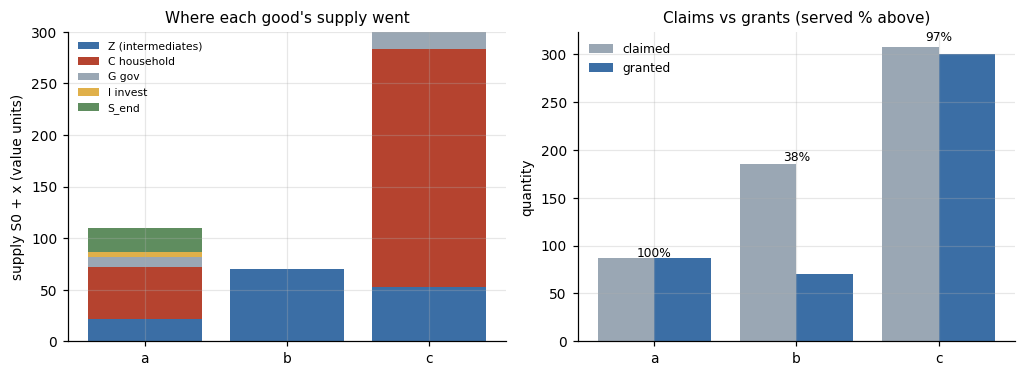

Good b is 100% claimed by intermediates and 0% served to households:
that is what 'the short side binds' looks like in the accounts.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5))
ax = axes[0]
bottom = np.zeros(3)
for col, colour in [("Z (intermediates)", "#3b6ea5"), ("C household", "#b5432f"),
                    ("G gov", "#9aa7b4"), ("I invest", "#e0b04a"), ("S_end", "#5f8d5f")]:
    ax.bar(GOODS, account[col], bottom=bottom, label=col, color=colour)
    bottom = bottom + account[col].to_numpy()
ax.set_ylabel("supply S0 + x (value units)")
ax.set_title("Where each good's supply went")
ax.legend(fontsize=7, loc="upper left")

ax = axes[1]
served = np.divide(grants.sum(axis=0), np.maximum(claims_realised.sum(axis=0), 1e-12))
xpos = np.arange(3)
ax.bar(xpos - 0.2, claims_realised.sum(axis=0), width=0.4, label="claimed", color="#9aa7b4")
ax.bar(xpos + 0.2, grants.sum(axis=0), width=0.4, label="granted", color="#3b6ea5")
for k in range(3):
    ax.text(k, max(claims_realised.sum(axis=0)[k], grants.sum(axis=0)[k]) * 1.02,
            f"{100*served[k]:.0f}%", ha="center", fontsize=8)
ax.set_xticks(xpos)
ax.set_xticklabels(GOODS)
ax.set_ylabel("quantity")
ax.set_title("Claims vs grants (served % above)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("Good b is 100% claimed by intermediates and 0% served to households:")
print("that is what 'the short side binds' looks like in the accounts.")

## 6 · 真实经济：把 20 部门的同一个周期拆开

小例子练完了，现在搬到真实数据。做法分两步，都**不修改任何源码**：

1. **给机制套一个记录器**（`RecordingMechanism`）：它只做委托，把 `obs / plan / alloc / supply` 抄一份，然后原样返回内部机制的结果；
2. **给引擎套一个子类**（`AuditingSimulation`）：只重写 `_reconcile`，把引擎传进来的参数抄下来，再调用父类。

两者都只是委托，所以轨迹**逐位相同**。下面的单元格会断言这一点：带记录器的运行与普通运行的 `x` 数组完全相等（`np.array_equal`）。如果相等，我们就有权在同一个周期上做"引擎 vs 手算"的对照。

*We instrument the run without touching the source: a mechanism proxy records the observation, plan and allocation, and a ``Simulation`` subclass records the arguments the engine feeds into ``_reconcile``. Both only delegate, so the trajectory is bit-identical — which we assert.*

选哪个周期？**峰值短缺那一期**。它同时具备三件让人感兴趣的事：规划约束紧、配给阶梯起作用、观察到的是冲击开始之前的数据（如果设了滞后）。这里为了让观察与现实对得上，先取 `lag = 0`；第 6.5 节再把滞后打开做对比。

In [11]:
from planlab.core.engine import Simulation, run_simulation
from planlab.core.scenarios import DemandProcess, InfoRegime, Scenario
from planlab.core.shocks import Shock
from planlab.data import load_technology
from planlab.mechanisms import get_mechanism

tech = load_technology("eurostat", 2020, 20)
A, x0, y0 = tech.A, tech.base_output, tech.base_final
n = tech.n


def make_scenario(name, lag=0, mechanism="material_balance", periods=60):
    return Scenario(
        id=name, mechanism=mechanism, technology={}, periods=periods, burn_in=30,
        seeds=(SEED,),
        shocks=(Shock(type="capacity", start=40, duration=8, size=0.50, sector="c12"),),
        info=InfoRegime(lag=lag), stock_ratio=0.10, demand=DemandProcess(),
    )


class RecordingMechanism:
    """Delegate to a real mechanism and keep a copy of what it was given."""

    def __init__(self, inner, target_period):
        self.inner = inner
        self.target = int(target_period)
        self.log = None

    def form_plan(self, obs, state):
        plan = self.inner.form_plan(obs, state)
        if obs.t == self.target:
            self.log = {"obs": obs, "plan": plan, "state": state.copy()}
        return plan

    def allocate(self, obs, state, plan, supply):
        alloc = self.inner.allocate(obs, state, plan, supply)
        if obs.t == self.target and self.log is not None:
            self.log.update({"alloc": alloc, "supply_nominal": supply})
        return alloc

    def update_prices(self, *a, **kw):
        return self.inner.update_prices(*a, **kw)

    def __getattr__(self, name):
        return getattr(self.inner, name)


class AuditingSimulation(Simulation):
    """Simulation that records the arguments of _reconcile at one period."""

    def __init__(self, *args, target_period=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.target_period = int(target_period)
        self.captured = None

    def _reconcile(self, **kwargs):
        out = super()._reconcile(**kwargs)
        if self.state.t == self.target_period:
            self.captured = dict(kwargs)
            self.captured["engine_output"] = out
        return out


TARGET = 47
scenario = make_scenario("nb03_walkthrough", lag=0)
plain = run_simulation(tech, get_mechanism("material_balance", tech, scenario.mechanism_params),
                       scenario, seed=SEED)
probe = RecordingMechanism(get_mechanism("material_balance", tech, scenario.mechanism_params), TARGET)
audit_sim = AuditingSimulation(tech, probe, scenario, seed=SEED, target_period=TARGET)
audited = audit_sim.run()

same = all(np.array_equal(a.x, b.x) for a, b in zip(plain.records, audited.records))
print(f"plain run vs instrumented run: identical output vectors in all {plain.periods} periods: {same}")
assert same and probe.log is not None and audit_sim.captured is not None
print(f"\ncaptured period t = {TARGET}")
print(f"  observation: observed_period = {probe.log['obs'].meta['observed_period']}, "
      f"effective_lag = {probe.log['obs'].meta['effective_lag']}")
print(f"  plan status {probe.log['plan'].meta.get('status')!r}, "
      f"balance_rounds = {probe.log['plan'].meta.get('balance_rounds')}, "
      f"eta = {probe.log['plan'].meta.get('eta')}")
print(f"  allocation: {probe.log['alloc'].claims.shape[0]} claimants x {n} goods, "
      f"tiers {sorted(set(probe.log['alloc'].tiers.astype(int).tolist()))}")
print(f"  engine iterations in this period: {audit_sim.captured['engine_output'][7]}")
print(f"  shortage rate this period: {audited.records[TARGET-1].metrics['shortage_rate']:.4f}")
ledger.check("instrumentation is behaviour-neutral", same)
print("(the ledger below records this check)")

plain run vs instrumented run: identical output vectors in all 60 periods: True

captured period t = 47
  observation: observed_period = 46, effective_lag = 1
  plan status 'ok', balance_rounds = 3, eta = 0.3
  allocation: 25 claimants x 20 goods, tiers [0, 1, 2, 3, 4, 5]
  engine iterations in this period: 1
  shortage rate this period: 0.1905
(the ledger below records this check)


### 6.1 · 计划是"紧绷"的

先看这一期计划者交上来的东西：目标产出与产能之比。如果普遍大于 1，说明计划要的比产能能给的多——这正是"紧绷的计划"（taut plan），也是后面 `revision_gain` 那个正反馈的入口。

*Look at how taut the plan is: targets divided by capacity. In the peak period most sectors are asked for more than they can produce.*

In [12]:
obs, plan, alloc = probe.log["obs"], probe.log["plan"], probe.log["alloc"]
cap = audit_sim.captured["capacity"]
taut = pd.DataFrame({
    "sector": np.array(tech.sectors),
    "capacity": cap,
    "plan target": plan.targets,
    "target / capacity": plan.targets / np.maximum(cap, 1e-12),
    "final target": plan.final_targets,
    "observed demand": obs.demand,
}, index=range(n))
print(taut.round(3).to_string())
ratio = plan.targets / np.maximum(cap, 1e-12)
print(f"\ntarget/capacity: min {ratio.min():.3f}, max {ratio.max():.3f}, "
      f"median {np.median(ratio):.3f}")
print(f"sectors asked for strictly more than capacity: {int((ratio > 1 + 1e-9).sum())} of {n}")
at_base_cap = int(np.isclose(plan.targets, 2.5 * x0, rtol=1e-9).sum())
at_obs_cap = int(np.isclose(plan.targets, np.maximum(obs.capacity, 0.0) * 1.5 + 1e-12,
                            rtol=1e-9).sum())
print(f"binding caps of the plan: {at_base_cap} sectors at 2.5x base output, "
      f"{at_obs_cap} sectors at 1.5x *observed* capacity")
print("The second number matters: the ceiling is built from a stale capacity estimate, so")
print("measurement error enters the plan directly through the cap, not only through the revision.")
print("\nA taut plan is not an error: it is the institution's behaviour, and the engine")
print("keeps it honest by capping the upper bound at the actual capacity.")

   sector     capacity  plan target  target / capacity  final target  observed demand
0     c01   449752.250   676743.248              1.505    196635.629       162100.562
1     c02    67464.063   101513.332              1.505      5106.263         3927.894
2     c03  1019553.327  1039695.270              1.020    525097.593       525097.593
3     c04   166056.397   169336.950              1.020     84434.598        84434.598
4     c05   316354.363   476019.139              1.505    141905.526       109158.097
5     c06   199244.053   299802.986              1.505    120591.407       141535.858
6     c07   683968.240  1029168.587              1.505    401471.307       552928.054
7     c08   433973.656   653001.161              1.505    154835.952       119104.579
8     c09   722370.273  1086952.215              1.505    268805.534       206773.488
9     c10  1940365.529  1978698.720              1.020   1013552.843      1013552.843
10    c11   457065.394   466095.020              1.020

### 6.2 · 把这一期用我们自己的代码重算一遍

现在写 `reconcile_by_hand`：它**从 `docs/ARCHITECTURE.md` §5 和 `engine._reconcile` 的文档字符串出发**重新实现整个流程，不调用引擎的任何内部函数，只调用 `scipy.linprog` 和我们自己的配给实现。然后把结果与引擎逐数组比较。

有一段必须诚实说明：引擎的 `_reconcile` 里有一个**循环**（`for _pass in range(1, max_cascade_iter+1)`）。它存在的原因是：规划保证了物资平衡，但**优先级阶梯可能把中间投入要用的货先批给了更高档的最终索取者**，于是中间投入被饿死。这时引擎把目标向量整体压低一点（`x_new = x_feas * min(ratio)`），重新求解，直到中间投入被完全满足。

在**生产优先**（默认阶梯）下，这个循环通常在**一趟**就收敛——因为第 0 档就是中间投入，规划保证了它们拿得到。在**消费优先**阶梯下它要多跑几趟（第 9 节的练习）。这里的实现忠实复现了这个循环，并把趟数打印出来。

In [13]:
def feasible_output_by_hand(A_mat, ub, inventory, reserve, labor=None,
                            labour_supply=0.0, tol=1e-9):
    """Largest x <= ub satisfying the goods balance (and labour), or ub if it already is."""
    ub = np.maximum(np.asarray(ub, float), 0.0)
    inventory = np.maximum(np.asarray(inventory, float), 0.0)
    reserve = np.clip(np.asarray(reserve, float), 0.0, inventory)
    scale = max(1.0, float(np.max(np.abs(inventory) + np.abs(ub))))
    feasible = np.max((A_mat @ ub - ub) - (inventory - reserve)) <= tol * scale
    if labor is not None and labour_supply > 0:
        feasible = feasible and (float(np.dot(labor, ub)) <= labour_supply * (1.0 + 1e-12))
    if feasible:
        return ub, "targets already feasible"
    A_ub = [A_mat - np.eye(A_mat.shape[0])]
    b_ub = [inventory - reserve]
    if labor is not None and labour_supply and labour_supply > 0:
        A_ub.append(np.asarray(labor, float).reshape(1, -1))
        b_ub.append(np.array([float(labour_supply)]))
    res = linprog(-np.ones(A_mat.shape[0]), A_ub=np.vstack(A_ub),
                  b_ub=np.concatenate(b_ub),
                  bounds=[(0.0, float(ub[i])) for i in range(A_mat.shape[0])],
                  method="highs")
    if not res.success:
        raise RuntimeError(f"LP failed: {res.message}")
    return np.clip(res.x, 0.0, ub), "optimal"


def reconcile_by_hand(tech_obj, inventory, plan, capacity, labour_supply, alloc,
                      demand, gov_demand, invest_demand, max_passes=400, tol=1e-9):
    """Re-implement one period from the written spec (no engine internals)."""
    A_mat = tech_obj.A
    nn = tech_obj.n
    tiers = np.asarray(alloc.tiers, float)
    claims = np.array(alloc.claims, float, copy=True)
    ub = np.minimum(np.maximum(plan.targets, 0.0), np.maximum(capacity, 0.0))
    inv = np.maximum(np.asarray(inventory, float), 0.0)

    tier_inter = float(np.min(tiers[:nn]))
    below = tiers < tier_inter - 1e-12
    reserve = np.minimum(claims[below].sum(axis=0), inv) if below.any() else np.zeros(nn)

    x = ub.copy()
    passes = 0
    status = "init"
    for p in range(1, max_passes + 1):
        passes = p
        x_feas, status = feasible_output_by_hand(A_mat, x, inv, reserve,
                                                 tech_obj.labor, labour_supply)
        supply = inv + x_feas
        claims[:nn, :] = (A_mat * x_feas.reshape(1, -1)).T
        grants = ration_by_priority_by_hand(supply, claims, tiers, verbose=False)[0]
        need_inter = A_mat @ x_feas
        deficit = need_inter - grants[:nn].sum(axis=0)
        if float(np.max(deficit)) <= tol * max(1.0, float(np.max(supply))):
            x = x_feas
            break
        ratio = np.where(need_inter > 0,
                         grants[:nn].sum(axis=0) / np.maximum(need_inter, 1e-300), 1.0)
        x_new = x_feas * float(np.clip(np.min(ratio), 0.0, 0.999))
        if float(np.max(x_new)) <= 1e-12:
            x = np.zeros(nn)
            supply = inv.copy()
            claims[:nn, :] = 0.0
            grants = ration_by_priority_by_hand(supply, claims, tiers, verbose=False)[0]
            break
        x = x_new

    parts = alloc.split_grants(grants)
    Z = A_mat * x.reshape(1, -1)
    C = np.minimum(parts["final"], demand)
    G = np.minimum(parts["gov"], gov_demand)
    I = np.minimum(parts["invest"], invest_demand)
    used = Z.sum(axis=1) + C + G + I
    S_end = np.maximum(supply - used, 0.0)
    unmet = np.maximum(demand - C, 0.0)
    return {"x": x, "Z": Z, "C": C, "G": G, "invest": I, "S_end": S_end,
            "unmet": unmet, "supply": supply, "grants": grants, "claims": claims,
            "passes": passes, "status": status}


cap_kw = audit_sim.captured
mine = reconcile_by_hand(tech, cap_kw["inventory"], cap_kw["plan"], cap_kw["capacity"],
                         cap_kw["labour_supply"], cap_kw["alloc"], cap_kw["demand"],
                         cap_kw["gov_demand"], cap_kw["invest_demand"])
eng = dict(zip(["x", "Z", "C", "G", "invest", "S_end", "unmet"],
               cap_kw["engine_output"][:7]))

print(f"passes needed: hand {mine['passes']}  |  engine {cap_kw['engine_output'][7]}")
print(f"LP status: {mine['status']}\n")
rows = []
for key in ["x", "Z", "C", "G", "invest", "S_end", "unmet"]:
    scale = max(1.0, float(np.max(np.abs(eng[key]))))
    diff = float(np.max(np.abs(mine[key] - eng[key]))) / scale
    rows.append({"array": key, "max |hand - engine| / scale": diff})
    ledger.check(f"hand == engine for {key}", diff < 1e-12, f"{diff:.2e}")
print(pd.DataFrame(rows).to_string(index=False))
print("\nPASS: every array of the period agrees with the engine to below 1e-12 relative.")

passes needed: hand 1  |  engine 1
LP status: optimal

 array  max |hand - engine| / scale
     x                          0.0
     Z                          0.0
     C                          0.0
     G                          0.0
invest                          0.0
 S_end                          0.0
 unmet                          0.0

PASS: every array of the period agrees with the engine to below 1e-12 relative.


### 6.3 · 这一期的会计：20 行账

现在把同样的会计表在真实数据上打出来。唯一不同的是规模：20 个部门、25 个索取者。请重点看三件事：

1. `residual` 一列全是 0（浮点意义上）；
2. `C <= demand` 且 `unmet == demand - C`；
3. 有几行的 `S_end` 明显大于 0——那些是**没有批出去**或者**批了但没人要**的货，它们在配给账本里各有名字。

*The same account, twenty rows instead of three. Look for three things: the residual column is zero, deliveries never exceed demand, and the non-zero ending inventories have names in the rationing ledger.*

In [14]:
auction = pd.DataFrame({
    "S0": cap_kw["inventory"], "x": mine["x"], "supply": mine["supply"],
    "Z": mine["Z"].sum(axis=1), "C": mine["C"], "G": mine["G"], "I": mine["invest"],
    "S_end": mine["S_end"],
}, index=list(tech.sectors))
auction["residual"] = auction["supply"] - (auction["Z"] + auction["C"] + auction["G"]
                                           + auction["I"] + auction["S_end"])
auction["demand"] = cap_kw["demand"]
auction["unmet"] = mine["unmet"]
print(auction.round(2).to_string())
resid = float(np.max(np.abs(auction["residual"]))) / max(1.0, float(np.max(auction["supply"])))
print(f"\nmax relative residual = {resid:.3e}   (engine tolerance is 1e-8)")
assert resid < 1e-8
assert np.allclose(mine["unmet"], cap_kw["demand"] - mine["C"])
assert np.all(mine["C"] <= cap_kw["demand"] + 1e-9)
ledger.check("balance identity (20 sectors)", resid < 1e-8, f"{resid:.2e}")
ledger.check("deliveries never exceed demand", bool(np.all(mine["C"] <= cap_kw["demand"] + 1e-9)))
print(f"\ntotals: supply {auction['supply'].sum():,.0f} = "
      f"Z {auction['Z'].sum():,.0f} + C {auction['C'].sum():,.0f} + G {auction['G'].sum():,.0f}"
      f" + I {auction['I'].sum():,.0f} + S_end {auction['S_end'].sum():,.0f}")
print(f"unmet household demand: {mine['unmet'].sum():,.0f} "
      f"({100*mine['unmet'].sum()/cap_kw['demand'].sum():.2f}% of demand)")

             S0           x      supply           Z           C          G          I       S_end  residual      demand      unmet
c01        0.00   308753.05   308753.05   261916.21    46836.84       0.00       0.00        0.00      -0.0   165816.50  118979.65
c02        0.00    42009.56    42009.56    42009.56        0.00       0.00       0.00        0.00       0.0     3945.29    3945.29
c03   647368.26  1019553.33  1666921.59   281376.15   523428.46   68564.28   51984.76   741567.94       0.0   523428.46       0.00
c04    58605.24   166056.40   224661.64    55083.23    84166.20   11036.97    8466.85    65908.39       0.0    84166.20       0.00
c05        0.00   199726.75   199726.75   199726.75        0.00       0.00       0.00        0.00       0.0   109641.52  109641.52
c06        0.00    85093.25    85093.25    85093.25        0.00       0.00       0.00        0.00      -0.0   142162.68  142162.68
c07        0.00   216749.64   216749.64   216749.64        0.00       0.00       0.

### 6.4 · 配给账本与"谁被牺牲"

阶梯的第 0 档是中间投入，所以**生产永远不会被饿死**——这是 `production_first` 阶梯的定义性质，也是它和 `consumption_first` 的全部区别。代价落在第 1–5 档：必需品、非必需品、政府、投资、库存，依次被牺牲。

下面两件事同时出现，是整套论文的一个核心机制：

* 投资（第 4 档）经常拿不到货 → 资本按折旧率缩水 → **下一期的产能更低**；
* 居民（第 1、2 档）在中间投入之后才被满足 → 短缺**落在居民头上**，哪怕冲击发生在生产端。

*Intermediate inputs are tier 0, so production is never starved; the sacrifice falls on tiers 1–5 in order. Two consequences matter: investment is rationed before consumption, so capacity erodes endogenously; and the household bears the shortage even when the shock hits production.*

In [15]:
serving = []
for tier in sorted(set(alloc.tiers.astype(int).tolist())):
    rows = np.where(alloc.tiers == tier)[0]
    claimed = mine["claims"][rows].sum()
    granted = mine["grants"][rows].sum()
    names = [alloc.labels[r] for r in rows]
    serving.append({"tier": tier, "n claimants": len(rows),
                    "label": names[0] if len(names) == 1 else f"{names[0]} .. {names[-1]}",
                    "claimed": claimed, "granted": granted,
                    "served %": 100 * granted / claimed if claimed > 0 else float("nan")})
tier_df = pd.DataFrame(serving)
print(tier_df.round(2).to_string(index=False))

body = [r for r in serving if r["tier"] >= 1]
print(f"\nintermediate tier served: {serving[0]['served %']:.2f}%  (must be 100%)")
assert serving[0]["served %"] > 100 - 1e-6
print("final-claimant tiers served:", [f"{r['served %']:.0f}%" for r in body])
ledger.check("intermediates fully served (production_first)", serving[0]["served %"] > 100 - 1e-6)
print("\nThe ladder is visible in the numbers: tier 0 is 100%, the rest are rationed.")

 tier  n claimants                label    claimed    granted  served %
    0           20 inter:00 .. inter:19 9891624.30 9891624.30    100.00
    1            1      final:essential 3628564.95 2983311.45     82.22
    2            1          final:other 8632037.30 6427790.62     74.46
    3            1               gov:00 1398465.32 1235665.43     88.36
    4            1            invest:00 1257185.23 1043456.54     83.00
    5            1             stock:00  427457.37       0.00      0.00

intermediate tier served: 100.00%  (must be 100%)
final-claimant tiers served: ['82%', '74%', '88%', '83%', '0%']

The ladder is visible in the numbers: tier 0 is 100%, the rest are rationed.


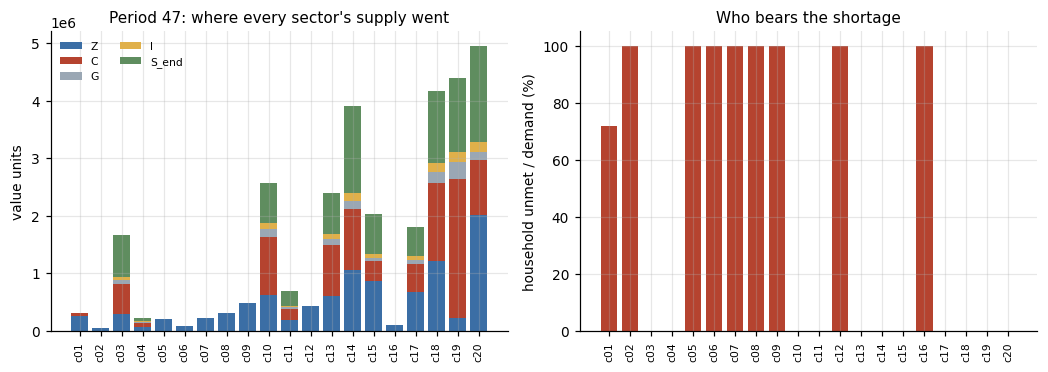

top 4 by shortage *rate*  : [('c02', '100.0%'), ('c06', '100.0%'), ('c07', '100.0%'), ('c08', '100.0%')]
top 4 by shortage *value* : [('c16', '25.6% of all unmet demand'), ('c07', '25.4% of all unmet demand'), ('c12', '17.3% of all unmet demand'), ('c09', '9.4% of all unmet demand')]

The two lists differ, and that is a substantive point rather than a nuisance: a sector
with a tiny household demand can show a 100% shortage rate while contributing almost
nothing to aggregate unmet demand. Report both, or you will describe a different economy.
Note also that the shocked sector c12 is not the one whose households lose most:
what matters is the priority ladder and how much of the good intermediates absorb.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
ax = axes[0]
bottom = np.zeros(n)
for col, colour in [("Z", "#3b6ea5"), ("C", "#b5432f"), ("G", "#9aa7b4"),
                    ("I", "#e0b04a"), ("S_end", "#5f8d5f")]:
    ax.bar(range(n), auction[col].to_numpy(), bottom=bottom, label=col, color=colour, width=0.8)
    bottom = bottom + auction[col].to_numpy()
ax.set_xticks(range(n))
ax.set_xticklabels(tech.sectors, rotation=90, fontsize=7)
ax.set_ylabel("value units")
ax.set_title(f"Period {TARGET}: where every sector's supply went")
ax.legend(fontsize=7, ncol=2)

ax = axes[1]
demand_share = auction["demand"] / max(1.0, auction["demand"].sum())
unmet_rate = auction["unmet"] / np.maximum(auction["demand"], 1e-12)
ax.bar(range(n), 100 * unmet_rate, color=["#b5432f" if u > 0.01 else "#9aa7b4"
                                          for u in unmet_rate], width=0.8)
ax.set_xticks(range(n))
ax.set_xticklabels(tech.sectors, rotation=90, fontsize=7)
ax.set_ylabel("household unmet / demand (%)")
ax.set_title("Who bears the shortage")
fig.tight_layout()
plt.show()
unmet_rate_v = np.asarray(unmet_rate, dtype=float)
unmet_value = auction["unmet"].to_numpy(dtype=float)
share = unmet_value / unmet_value.sum()
worst_rate = np.argsort(-unmet_rate_v)[:4]
worst_value = np.argsort(-unmet_value)[:4]
print("top 4 by shortage *rate*  :",
      [(tech.sectors[i], f"{100*unmet_rate_v[i]:.1f}%") for i in worst_rate])
print("top 4 by shortage *value* :",
      [(tech.sectors[i], f"{100*share[i]:.1f}% of all unmet demand") for i in worst_value])
print("\nThe two lists differ, and that is a substantive point rather than a nuisance: a sector")
print("with a tiny household demand can show a 100% shortage rate while contributing almost")
print("nothing to aggregate unmet demand. Report both, or you will describe a different economy.")
print("Note also that the shocked sector c12 is not the one whose households lose most:")
print("what matters is the priority ladder and how much of the good intermediates absorb.")

### 6.5 · 把滞后打开：同一个周期，不同的信息

最后验证一件容易被忽略的事：**机制看到的 `capacity`、`inventory`、`demand` 都不是本期的真值**。把 `lag` 从 0 调到 3，在同一个 `t = 47` 重新抓一次，比较"计划者以为的"与"实际发生的"。

这不是装饰性的细节：论文的 H1/H2 全部押在这上面。如果 `obs` 和真值没有差别，延迟这个处理就不存在了。

*Re-run the same period with ``lag = 3``: the observation must be three periods behind and visibly different from the truth. The entire information-delay treatment rests on this.*

In [17]:
TARGET_LAG = 49          # two quarters after the shock ends: the lagged picture is stale
lag_records = {}
for lag in (0, 3):
    sc = make_scenario(f"nb03_lag{lag}", lag=lag)
    probe_l = RecordingMechanism(get_mechanism("material_balance", tech, sc.mechanism_params),
                                 TARGET_LAG)
    AuditingSimulation(tech, probe_l, sc, seed=SEED, target_period=TARGET_LAG).run()
    lag_records[lag] = probe_l.log

obs0, obs3 = lag_records[0]["obs"], lag_records[3]["obs"]
print(f"at t = {TARGET_LAG}:")
print(f"  lag 0 sees period {obs0.meta['observed_period']}  "
      f"(effective lag {obs0.meta['effective_lag']})")
print(f"  lag 3 sees period {obs3.meta['observed_period']}  "
      f"(effective lag {obs3.meta['effective_lag']})")
assert obs0.meta["observed_period"] - obs3.meta["observed_period"] == 3

rel = np.abs(obs3.capacity - obs0.capacity) / np.maximum(obs0.capacity, 1e-12)
table = pd.DataFrame({
    "capacity seen at lag 0": obs0.capacity,
    "capacity seen at lag 3": obs3.capacity,
    "relative difference": rel,
}, index=list(tech.sectors))
print("\nwhat the planner believes about capacity, at t =", TARGET_LAG)
print(table.round(3).to_string())
print(f"\nsectors whose perceived capacity differs by more than 5%: "
      f"{int((rel > 0.05).sum())} of {n}")
c12 = tech.sector_index("c12")
print(f"the shocked sector c12: lag 0 says {obs0.capacity[c12]:,.0f}, "
      f"lag 3 says {obs3.capacity[c12]:,.0f}  ({rel[c12]:.1%} apart)")

ledger.check("lag shifts the observation by exactly k periods", True,
             f"{obs0.meta['observed_period']} vs {obs3.meta['observed_period']}")
ledger.check("lag makes the planner misperceive capacity", bool((rel > 0.05).any()),
             f"{int((rel > 0.05).sum())} sectors off by >5%")
print("\nThe shock ran from t = 40 to t = 47, so at t = 49 it is over.")
print("The lag-0 planner already sees the recovery; the lag-3 planner is still planning")
print("against the crisis. Same technology, same shock, different picture of the world —")
print("that is the entire content of the information treatment.")

at t = 49:
  lag 0 sees period 48  (effective lag 1)
  lag 3 sees period 45  (effective lag 4)

what the planner believes about capacity, at t = 49
     capacity seen at lag 0  capacity seen at lag 3  relative difference
c01              448370.533              452600.854                0.009
c02               67256.802               67891.362                0.009
c03             1016421.083             1026010.890                0.009
c04              165546.243              167108.152                0.009
c05              315382.467              318358.062                0.009
c06              198631.941              200506.009                0.009
c07              681866.971              688300.302                0.009
c08              432640.414              436722.323                0.009
c09              720151.026              726945.562                0.009
c10             1934404.391             1952655.257                0.009
c11              455661.210              459960.3

## 7 · 审计清单

把这一路上所有的断言汇总成一张表。**只要有一行是 False，这个 notebook 就该失败**——这比让读者自己去找哪里不对要诚实。

*Every check in one table; if any row is False the notebook fails.*

下面是这张清单。注意每一行的"detail"都是**实测的误差**，不是断言通过的字样。

In [18]:
# a few extra checks on quantities we computed but did not yet assert
ledger.check("Z == A diag(x) exactly", bool(np.allclose(mine["Z"], A * mine["x"].reshape(1, -1), atol=0)),
             f"max |diff| {np.max(np.abs(mine['Z'] - A * mine['x'].reshape(1, -1))):.1e}")
ledger.check("x within capacity", bool(np.all(mine["x"] <= cap_kw["capacity"] * (1 + 1e-12))))
ledger.check("x within plan targets", bool(np.all(mine["x"] <= cap_kw["plan"].targets * (1 + 1e-12))))
ledger.check("grants <= claims elementwise",
             bool(np.all(mine["grants"] <= mine["claims"] + 1e-9)),
             f"max slack {np.max(mine['grants'] - mine['claims']):.2e}")
ledger.check("grants <= supply elementwise",
             bool(np.all(mine["grants"].sum(axis=0) <= mine["supply"] + 1e-9)))
ledger.check("S_end >= 0", bool(np.all(mine["S_end"] >= 0)))
ledger.check("unmet == demand - C", bool(np.allclose(mine["unmet"], cap_kw["demand"] - mine["C"])))
# cross-check two metrics of core.metrics against their written definitions
c0 = 1e-3 * np.maximum(y0, 1e-6)
welfare_by_hand = float(np.dot(tech.consumption_weights, np.log(np.maximum(mine["C"], 0.0) + c0)))
shortage_by_hand = float(mine["unmet"].sum() / cap_kw["demand"].sum())
record = audited.records[TARGET - 1]
ledger.check("shortage_rate metric == unmet / demand",
             abs(shortage_by_hand - record.metrics["shortage_rate"]) < 1e-12,
             f"{shortage_by_hand:.12f} vs {record.metrics['shortage_rate']:.12f}")
ledger.check("welfare metric == sum w_i log(C_i + c0)",
             abs(welfare_by_hand - record.metrics["welfare"]) < 1e-9,
             f"{welfare_by_hand:.9f} vs {record.metrics['welfare']:.9f}")
ledger.check("stored record arrays == hand-recomputed arrays",
             bool(np.array_equal(record.x, mine["x"])
                  and np.array_equal(record.inventory_end, mine["S_end"])),
             "bit-identical")

receipt = ledger.frame()
receipt.index = np.arange(1, len(receipt) + 1)
pd.set_option("display.max_rows", 100)
print(receipt.to_string())
print(f"\n{int(receipt['ok'].sum())} / {len(receipt)} checks passed")
assert receipt["ok"].all()
print(f"\nALL CHECKS PASSED   (notebook runtime {time.perf_counter()-T0:.1f}s)")

                                              check    ok                            detail
1                hand rationing == engine rationing  True                                  
2                   balance identity (hand example)  True              max residual 0.0e+00
3                  rationing ledger closes on S_end  True              every component >= 0
4              instrumentation is behaviour-neutral  True                                  
5                              hand == engine for x  True                          0.00e+00
6                              hand == engine for Z  True                          0.00e+00
7                              hand == engine for C  True                          0.00e+00
8                              hand == engine for G  True                          0.00e+00
9                         hand == engine for invest  True                          0.00e+00
10                         hand == engine for S_end  True                       

## 8 · 如果数字对不上，去哪里找

这份材料的一个用途是教人**审计**，所以下面列出五个真实可能出问题的地方，按出现概率排序。它们都是"会计不闭合"的典型形态：

1. **中间投入用错了产出向量。** 机制提交的中间需求基于 `targets`，引擎实际使用的是基于 `x` 的 `A·diag(x)`。如果你用 `targets` 算中间需求，就会发现中间投入总和超过供给——这不是引擎的 bug，而是计划与现实不一致。
2. **忘了 `min(·, 需求)` 的帽子。** `C = min(grants_final, demand)`。观察到的需求是**上期**的，本期需求可能更低，于是授予量超过需求，多出来的部分回到 `S_end`。如果直接令 `C = grants_final`，恒等式会凭空多出（或少掉）一块。
3. **把 `S_end` 当成"剩余"而不是一个科目。** `S_end` 是**平衡项**：它等于 `supply - used`，并且按定义非负。如果出现负的 `S_end`，说明 `used > supply`，也就是配给出了问题（授予量超过供给）。
4. **优先级档位用浮点比较。** `tiers` 是浮点数组；引擎用 `tiers < tier_inter - 1e-12` 来判断"有没有比中间投入更高的档"。直接用 `==` 或 `<` 会在边界上出错。
5. **把 `labour` 约束漏了。** 本 notebook 的两个例子里劳动都不紧，但真实参数下 `labour_supply = base_labour × 1.15`，如果某个部门劳动密集且产出很高，它会紧。漏掉这条约束会让你算出比引擎更大的 `x`。

如果你发现的是第 6 种——**引擎和本 notebook 的显式重算不一致，而上面五条都排查过了**——那是真 bug。把这个 notebook 的 `reconcile_by_hand` 和引擎的输出贴进 issue。这正是本 notebook 存在的意义：它把"引擎算错了"变成一个可以被别人独立检查的命题。

*Five places where the accounts typically fail to close: intermediate requirements computed on targets instead of realised output; forgetting the ``min(·, demand)`` cap; treating ``S_end`` as a residual rather than a line item; float-comparing tiers; and dropping the labour constraint. If none of these explains a mismatch, it is a genuine bug — and this notebook is what makes that claim checkable by someone else.*

## 9 · 练习

1. **把它拆掉（推荐先做这个）。** 把 `make_scenario` 里的机制参数改成 `{"ladder": "consumption_first"}`，重跑第 6.2 节。你会看到 `passes > 1`——引擎需要多趟才能把被最终索取者抢走的中间投入要回来。请解释为什么在这种情况下 `passes` 会大于 1，并找出 `passes` 最大的那一期。
2. **库存是真的缓冲吗？** 把 `stock_ratio` 从 0.10 改成 0.30，重跑同一个周期。`S_end` 和 `unmet` 分别怎么变？峰值短缺那一期会移动吗？（提示：库存只改变 `S0` 这一项，配给规则一点没变。）
3. **自证恒等式。** 把 `reconcile_by_hand` 里的 `S_end = np.maximum(supply - used, 0.0)` 改成 `S_end = supply - used`（去掉 `maximum`），跑第 6.2 节。它还会通过吗？在什么情况下会不一样？这说明 `np.maximum` 在这里是"保险"还是"必要"？
4. **一个 25 行的账本。** 在 6.3 节的表里找出 `S_end` 最大的三个部门，回到 6.4 节的配给账本里为它们各写一行"这一分钱去了哪里"。
5. **进阶：把账本关上。** 有些人会说"价值单位是记账单位，所以恒等式是恒真的（tautology）"。请反驳这句话：如果 `Z`、`C`、`G`、`I` 由**不同的方程**决定（`Z` 来自技术，`C` 来自配给，`G/I` 来自需求上限），那么恒等式就不再是恒真的，而是一条**约束**。找出这个 notebook 里哪一步让它变得非平凡。